In [1]:
import os, sys
import numpy as np
import pandas as pd

    from Bio import SeqIO

# log library versions and working dir
from scipy.version import full_version as spversion
from Bio import __version__ as bioversion

print("Python:    ", sys.version)
print("Numpy:     ", np.__version__)
print("Scipy:     ", spversion)
print("Biopython: ", bioversion)
print("Workdir:   ", os.getcwd())

Python:     3.9.13 (main, Aug 25 2022, 23:51:50) [MSC v.1916 64 bit (AMD64)]
Numpy:      1.23.5
Scipy:      1.9.2
Biopython:  1.81
Workdir:    C:\Projects\MHC_predictor\experiments\generate_data


# Params

In [2]:
CLASSES_TO_GENERATE = ['I','II']
ORGANISMS_TO_GENERATE = ['Human', 'Mouse']
PER_CLASS_MIN_MAX_LENGTHS = {
    'I': {'min':8, 'max':14},
    'II': {'min':11, 'max':27}
}
PATH_TO_SAVE_DATA = 'G:/My Drive/Work/ITMO/data/decoy/'

In [3]:
per_organism_total_file = {
    'Human':  "G:/My Drive/Work/ITMO/data/gencode file/gencode.v43.pc_translations.fa",
    'Mouse':  "G:/My Drive/Work/ITMO/data/gencode file/gencode.vM32.pc_translations.fa"

}

# Read all proteins

In [14]:
# reading with BioPython

per_organism_proteins = {
    organism: [protein for protein in SeqIO.parse(
        per_organism_total_file[organism],
            "fasta"
    ) ] for organism in ORGANISMS_TO_GENERATE
}
print("lengths",[len(proteins) for proteins in per_organism_proteins.values()])

lengths [111276, 66800]


In [15]:
# check if all fasta ID lines have the same number of 'fields'
for organism in ORGANISMS_TO_GENERATE:
    numSegmentsInName = pd.Series([len(protein.id.split('|')) for protein in per_organism_proteins[organism]])
    print(numSegmentsInName.value_counts().to_string())

8    111276
8    66800


# Create data frames

In [16]:
# create a dataframe
gencodeFastaIdFields = [
    'unknown_id',
    'transcript_id',
    'gene_id',
    'Havana_gene_id',
    'Havana_transcript_id',
    'transcript_name',
    'gene_name',
    'length'
]
per_organism_proteome = {
    # we throw away the lengthy first 5 fields; transcript_name is anyway unique
    organism: pd.DataFrame(
    [protein.id.split('|')[5:8] + [str(protein.seq)] for protein in per_organism_proteins[organism]],
    columns = gencodeFastaIdFields[5:8] + ['sequence'],
) for organism in ORGANISMS_TO_GENERATE
}

for organism in ORGANISMS_TO_GENERATE:
    df_proteome = per_organism_proteome[organism]
    df_proteome.length = pd.to_numeric(df_proteome.length)
    per_organism_proteome[organism] = df_proteome

In [17]:
df_proteome.head()

,transcript_name,gene_name,length,sequence
0,Xkr4-201,Xkr4,647,MAAKSDGRLKMKKSSDVAFTPLQNSDNSGSVQGLAPGLPSGSGAED...
1,Rp1-202,Rp1,1371,MLEKLQVSPKMSDTPSTSFSMIHLTSEGQVPSPRHSNITHPVVAKR...
2,Rp1-201,Rp1,2095,MSDTPSTSFSMIHLTSEGQVPSPRHSNITHPVVAKRISFYKSGDPQ...
3,Sox17-201,Sox17,419,MSSPDAGYASDDQSQPRSAQPAVMAGLGPCPWAESLSPLGDVKVKG...
4,Sox17-208,Sox17,291,MQDHPNYKYRPRRRKQVKRMKRVEGGFLHALVEPQAGALGPEGGRV...


# Inspect original names

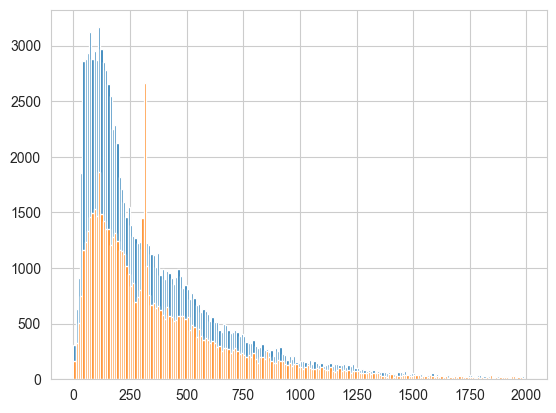

In [18]:
# distribution of lengths
for organism in ORGANISMS_TO_GENERATE:
    per_organism_proteome[organism].length.hist(bins = [x for x in range(0,2000,10)]);

# Print some of sequences

In [19]:
# print some peptides:
for organism in ORGANISMS_TO_GENERATE:
    for index,row in per_organism_proteome[organism][0:5].iterrows():
        print(row['transcript_name'])
        print(row['sequence'])

OR4F5-201
MKKVTAEAISWNESTSETNNSMVTEFIFLGLSDSQELQTFLFMLFFVFYGGIVFGNLLIVITVVSDSHLHSPMYFLLANLSLIDLSLSSVTAPKMITDFFSQRKVISFKGCLVQIFLLHFFGGSEMVILIAMGFDRYIAICKPLHYTTIMCGNACVGIMAVTWGIGFLHSVSQLAFAVHLLFCGPNEVDSFYCDLPRVIKLACTDTYRLDIMVIANSGVLTVCSFVLLIISYTIILMTIQHRPLDKSSKALSTLTAHITVVLLFFGPCVFIYAWPFPIKSLDKFLAVFYSVITPLLNPIIYTLRNKDMKTAIRQLRKWDAHSSVKF
OR4F29-201
MDGENHSVVSEFLFLGLTHSWEIQLLLLVFSSVLYVASITGNILIVFSVTTDPHLHSPMYFLLASLSFIDLGACSVTSPKMIYDLFRKRKVISFGGCIAQIFFIHVVGGVEMVLLIAMAFDRYVALCKPLHYLTIMSPRMCLSFLAVAWTLGVSHSLFQLAFLVNLAFCGPNVLDSFYCDLPRLLRLACTDTYRLQFMVTVNSGFICVGTFFILLISYVFILFTVWKHSSGGSSKALSTLSAHSTVVLLFFGPPMFVYTRPHPNSQMDKFLAIFDAVLTPFLNPVVYTFRNKEMKAAIKRVCKQLVIYKRIS
OR4F16-201
MDGENHSVVSEFLFLGLTHSWEIQLLLLVFSSVLYVASITGNILIVFSVTTDPHLHSPMYFLLASLSFIDLGACSVTSPKMIYDLFRKRKVISFGGCIAQIFFIHVVGGVEMVLLIAMAFDRYVALCKPLHYLTIMSPRMCLSFLAVAWTLGVSHSLFQLAFLVNLAFCGPNVLDSFYCDLPRLLRLACTDTYRLQFMVTVNSGFICVGTFFILLISYVFILFTVWKHSSGGSSKALSTLSAHSTVVLLFFGPPMFVYTRPHPNSQMDKFLAIFDAVLTPFLNPVVYTFRNKEMKAAIKRVCKQLVIYKRIS
SAMD11-209
MPAV

# Shred proteome sequences

In [20]:
# fragment the proteome
def shredProteins(listOfProteins, minLength, maxLength):
    """Cut all proteins in the list in fragments of length uniformly distributed in the given range"""

    assert (minLength <= maxLength), "Invalid length range"

    fragments = []
    for protein in listOfProteins:
        while(True):
            if (len(protein) < minLength):
                # do not gather short rubbish
                break
            fragmentLength = np.random.randint(minLength, maxLength + 1)
            fragments.append(protein[0:fragmentLength])
            protein = protein[fragmentLength:]
    return fragments

In [21]:
NUM_ITERATIONS = 3
per_organism_per_class_peptides = dict()

for organism in ORGANISMS_TO_GENERATE:
    print(f"Organism {organism}")
    per_organism_per_class_peptides[organism] = dict()
    for class_to_generate in CLASSES_TO_GENERATE:
        print(f"Class {class_to_generate}")
        min_length = PER_CLASS_MIN_MAX_LENGTHS[class_to_generate]['min']
        max_length = PER_CLASS_MIN_MAX_LENGTHS[class_to_generate]['max']
        fragments = list()
        for i in range(NUM_ITERATIONS):
            fragments.extend(shredProteins(per_organism_proteome[organism].sequence, min_length, max_length))
        per_organism_per_class_peptides[organism][class_to_generate] = fragments
        lengths = [len(f) for f in fragments]
        print("Number of peptides:", len(fragments))
        print("Length range: {}-{}".format(min(lengths), max(lengths)))

Organism Human
Class I
Number of peptides: 11941758
Length range: 8-14
Class II
Number of peptides: 6938323
Length range: 11-27
Organism Mouse
Class I
Number of peptides: 7734921
Length range: 8-14
Class II
Number of peptides: 4493376
Length range: 11-27


## Save to files

In [22]:
if not os.path.exists(PATH_TO_SAVE_DATA):
    os.makedirs(PATH_TO_SAVE_DATA)

for organism in ORGANISMS_TO_GENERATE:
    for class_to_generate in CLASSES_TO_GENERATE:
        fragments =  per_organism_per_class_peptides[organism][class_to_generate]
        with open(f'{PATH_TO_SAVE_DATA}/decoy-{organism.lower()}-class-{class_to_generate.lower()}.txt', 'w') as f:
            for fragment in fragments:
                f.write(fragment + '\n')


In [23]:
df = pd.DataFrame({"peptide": fragments})
df['length'] = df.peptide.str.len()
df.length.value_counts()

11    274110
12    272869
13    271789
14    269951
15    269211
16    268446
17    267195
18    265652
19    265093
20    262537
21    261313
22    261183
23    259443
24    257693
25    256999
26    255567
27    254325
Name: length, dtype: int64